# 05 — Visualization แบบในบทเรียน: sliding DFT/SST และ t-SNE embedding

บทนี้เพิ่มภาพสองชนิดตามตัวอย่างที่ต้องการ:

1. ภาพอธิบายว่าเรานำหน้าต่างเลื่อนไปบน EEG แล้วคำนวณ spectrum อย่างไร ก่อนเปรียบเทียบกับ SST จริง
2. t-SNE ของ **Stage-2 embeddings ที่อนุมานจาก checkpoint r19 จริง** สำหรับ seed 42 และ 43

ไฟล์ embedding ถูกสร้างด้วย CPU-only post-hoc inference จาก test split เดิม ไม่มีการฝึกต่อ ไม่มี optimizer step และไม่แก้ canonical run artifacts

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "paper_faithful").is_dir())
sys.path.insert(0, str(ROOT / "walkthrough"))

import matplotlib.pyplot as plt
import numpy as np
from walkthrough_lib import *

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print(f"Project root : {PROJECT_ROOT}")
print(f"Bulk artifacts: {BULK_ROOT}")

Project root : C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction
Bulk artifacts: E:\blp\sleep_stage_reproduction


## 1. จาก sliding DFT ไปสู่ SST

ด้านซ้ายใช้ EEG จริงจาก `SC4001E0-PSG.edf` เพื่อสาธิต windowing และ STFT/DFT ส่วนด้านขวาอ่าน SST tensor ที่สร้างจริงจาก cache รูปนี้จึงช่วยอธิบายแนวคิด แต่ไม่ได้กล่าวว่า STFT ด้านซ้ายเท่ากับ SST ด้านขวา

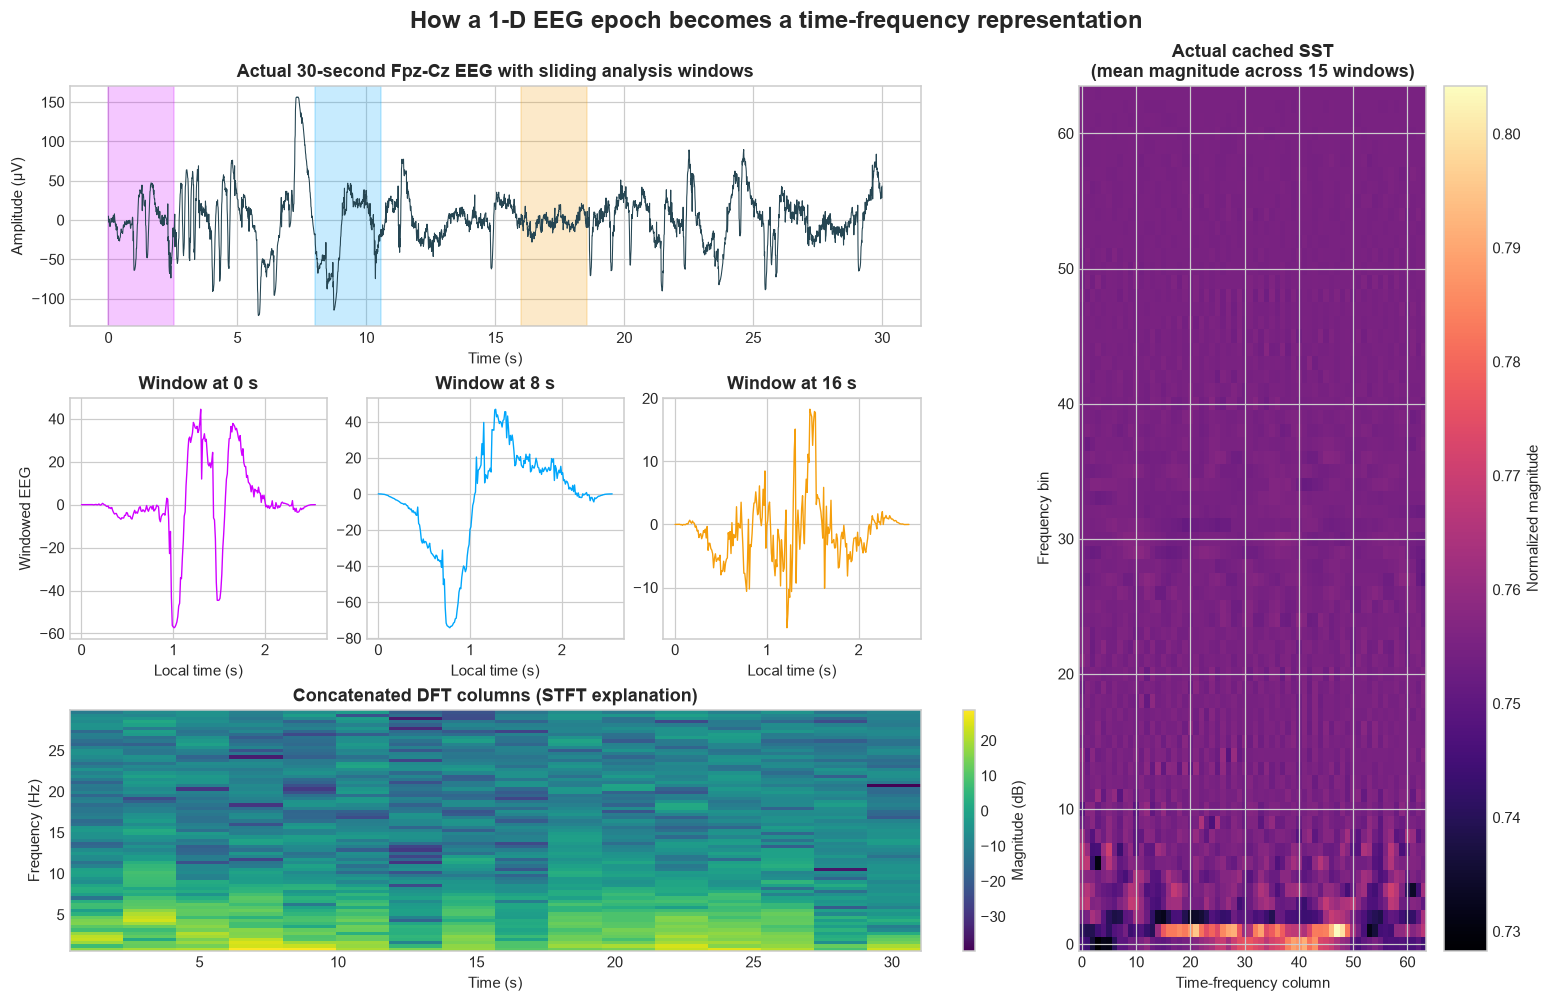

Saved: C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\walkthrough\figures\01_sliding_dft_and_actual_sst.png


In [2]:
import mne
from scipy import signal as scipy_signal

figures_dir = PROJECT_ROOT / "walkthrough" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

edf_path = sorted((PROJECT_ROOT / "data" / "sleep-edf").glob("*-PSG.edf"))[0]
raw = mne.io.read_raw_edf(edf_path, preload=False, verbose="ERROR")
sfreq = float(raw.info["sfreq"])
eeg = raw.get_data(picks=["EEG Fpz-Cz"], start=0, stop=int(30 * sfreq))[0] * 1e6
time_s = np.arange(eeg.size) / sfreq

window_seconds = 2.56
window_samples = int(window_seconds * sfreq)
starts = [0, int(8 * sfreq), int(16 * sfreq)]
colors = ["#d000ff", "#00a6fb", "#f59e0b"]

fig = plt.figure(figsize=(14, 9), constrained_layout=True)
grid = fig.add_gridspec(3, 4, width_ratios=[1, 1, 1, 1.35])
ax_signal = fig.add_subplot(grid[0, :3])
ax_signal.plot(time_s, eeg, color="#264653", lw=0.7)
for start, color in zip(starts, colors):
    ax_signal.axvspan(start / sfreq, (start + window_samples) / sfreq, color=color, alpha=0.22)
ax_signal.set(title="Actual 30-second Fpz-Cz EEG with sliding analysis windows", xlabel="Time (s)", ylabel="Amplitude (µV)")

for column, (start, color) in enumerate(zip(starts, colors)):
    ax = fig.add_subplot(grid[1, column])
    segment = eeg[start : start + window_samples]
    local_time = np.arange(segment.size) / sfreq
    ax.plot(local_time, segment * np.hanning(segment.size), color=color, lw=0.9)
    ax.set(title=f"Window at {start/sfreq:.0f} s", xlabel="Local time (s)")
    if column == 0:
        ax.set_ylabel("Windowed EEG")

freq, times, zxx = scipy_signal.stft(eeg, fs=sfreq, window="hann", nperseg=256, noverlap=64, boundary=None)
mask = (freq >= 0.5) & (freq <= 30)
ax_stft = fig.add_subplot(grid[2, :3])
mesh = ax_stft.pcolormesh(times, freq[mask], 20 * np.log10(np.abs(zxx[mask]) + 1e-9), shading="auto", cmap="viridis")
ax_stft.set(title="Concatenated DFT columns (STFT explanation)", xlabel="Time (s)", ylabel="Frequency (Hz)")
fig.colorbar(mesh, ax=ax_stft, label="Magnitude (dB)")

stage3, _, _ = load_sst_example("PAPER_STAGE3_V1")
sst_magnitude = np.sqrt(stage3[:, :, :, 0] ** 2 + stage3[:, :, :, 1] ** 2).mean(axis=0)
ax_sst = fig.add_subplot(grid[:, 3])
image = ax_sst.imshow(sst_magnitude, origin="lower", aspect="auto", cmap="magma")
ax_sst.set(title="Actual cached SST\n(mean magnitude across 15 windows)", xlabel="Time-frequency column", ylabel="Frequency bin")
fig.colorbar(image, ax=ax_sst, label="Normalized magnitude")

fig.suptitle("How a 1-D EEG epoch becomes a time-frequency representation", fontsize=16, weight="bold")
figure_path = figures_dir / "01_sliding_dft_and_actual_sst.png"
fig.savefig(figure_path, dpi=170, bbox_inches="tight")
plt.show()
print("Saved:", figure_path)

## 2. ตรวจ provenance ของ embedding

แต่ละไฟล์ต้องผูกกับ completed r19 run, test split hash และ Stage-2 checkpoint hash ก่อนนำไปวาด

In [3]:
import hashlib

artifacts_dir = PROJECT_ROOT / "walkthrough" / "artifacts"
embedding_files = sorted(artifacts_dir.glob("r19_seed*_stage2_test_embeddings.npz"))
assert len(embedding_files) == 2, "ต้องมี embedding artifacts ของ r19 สอง seed"

provenance_rows = []
for path in embedding_files:
    provenance = load_json(path.with_suffix(".json"))
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == provenance["output_npz_sha256"]
    assert provenance["training_performed"] is False
    provenance_rows.append({
        "run_id": provenance["run_id"],
        "seed": provenance["model_seed"],
        "split": provenance["split"],
        "points": provenance["embedding_count"],
        "dimensions": provenance["embedding_dimensions"],
        "training": provenance["training_performed"],
    })
print_records(provenance_rows, ["seed", "split", "points", "dimensions", "training", "run_id"])

seed | split | points | dimensions | training | run_id                                                     
-----+-------+--------+------------+----------+------------------------------------------------------------
42   | test  | 1536   | 256        | False    | paper-text-v1-multiseed-cap128-r19-20260905-split42-model42
43   | test  | 1536   | 256        | False    | paper-text-v1-multiseed-cap128-r19-20260905-split43-model43


## 3. ลด 256 มิติเป็น 2 มิติด้วย t-SNE

ก่อน t-SNE เราทำ L2 normalization แบบเดียวกับ geometry ที่ contrastive loss ใช้ แล้วลดด้วย PCA เหลือ 50 มิติเพื่อให้เสถียรขึ้น สีคือ sleep stage จริงของแต่ละ window

> t-SNE ใช้ดูรูปทรงและการทับซ้อนของกลุ่มเท่านั้น ระยะและขนาดกลุ่มบนภาพไม่ใช่ accuracy และไม่ควรใช้แทนการประเมินบน test set

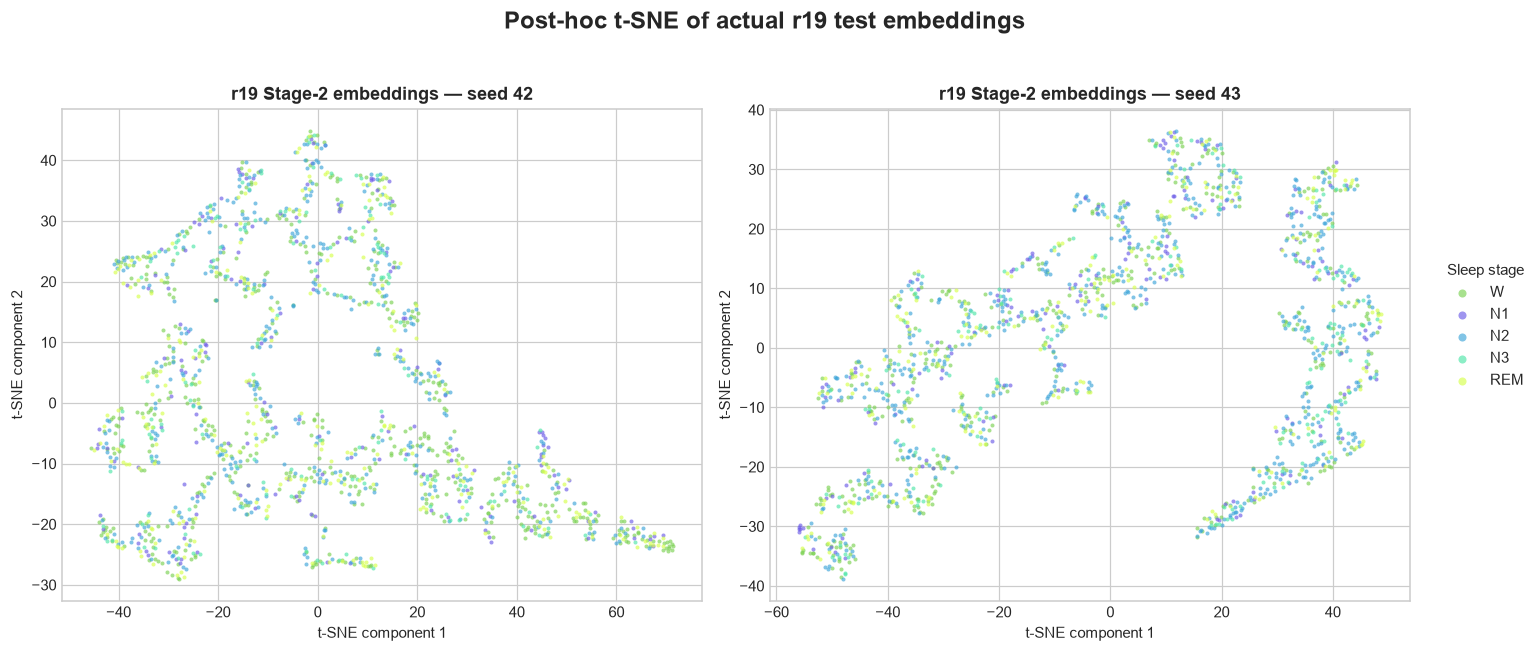

Saved: C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction\walkthrough\figures\02_r19_stage2_tsne.png


In [4]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize

palette = {"W": "#7ad151", "N1": "#6c5ce7", "N2": "#3da5d9", "N3": "#4ee6a8", "REM": "#d6ff4b"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=False, sharey=False)

for ax, path in zip(axes, embedding_files):
    artifact = np.load(path)
    embeddings = artifact["embeddings"].astype(np.float64)
    labels = artifact["labels"].astype(int)
    model_seed = int(artifact["model_seed"])
    unit = normalize(embeddings, norm="l2")
    reduced = PCA(n_components=50, random_state=42).fit_transform(unit)
    points = TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        max_iter=1000,
        random_state=42,
    ).fit_transform(reduced)
    for class_index, label_name in enumerate(LABELS):
        selected = labels == class_index
        ax.scatter(points[selected, 0], points[selected, 1], s=7, alpha=0.65, c=palette[label_name], label=label_name, linewidths=0)
    ax.set(title=f"r19 Stage-2 embeddings — seed {model_seed}", xlabel="t-SNE component 1", ylabel="t-SNE component 2")

handles, legend_labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="center right", title="Sleep stage", markerscale=2)
fig.suptitle("Post-hoc t-SNE of actual r19 test embeddings", fontsize=16, weight="bold")
fig.tight_layout(rect=(0, 0, 0.93, 0.95))
tsne_path = figures_dir / "02_r19_stage2_tsne.png"
fig.savefig(tsne_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", tsne_path)

## 4. อ่านภาพอย่างไร

- ถ้าสีแต่ละสีแยกเป็นเกาะชัด representation จะมีโครงสร้างที่แยกคลาสได้ง่ายกว่า
- ถ้าสีทับกันมาก แสดงว่า Stage-2 embedding ยังแยก sleep stages ได้ไม่ดีใน pilot นี้
- ค่า silhouette test ของ r19 เป็นลบทั้งสอง seed (`-0.0818` และ `-0.0938`) ซึ่งสอดคล้องกับการทับซ้อนที่เห็น
- นี่เป็น **cap128 epoch-random pilot** ไม่ใช่ full-cohort result และไม่ใช่ subject-held-out result

ดังนั้นกราฟนี้ตอบว่า “representation ของ pilot มีรูปร่างอย่างไร” ไม่ได้ตอบว่า “โมเดลทำซ้ำ 83% สำเร็จหรือยัง”